## Практическое домашнее задание 2. Градиентный спуск своими руками

### Общая информация

Дата выдачи: 16.10.2026

Мягкий дедлайн: 16.11.2026 23:59 MSK

Жесткий дедлайн: 23.11.2026 23:59 MSK


### Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). **Максимально допустимая оценка за работу — 10 баллов.**

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо считываемые диаграммы.

Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

Для удобства проверки самостоятельно посчитайте свою максимальную оценку (исходя из набора решенных задач) и укажите ниже.

**Оценка**: 10


### О задании

В данном задании необходимо реализовать обучение линейной регрессии с помощью различных модификаций градиентного спуска. В файле `descents.py` вам нужно будет реализовать несколько классов для различных вариаций градиентного спуска, а именно:
* `VanillaGradientDescent`
* `StochasticGradientDescent`
* `SAGDescent`
* `MomentumDescent`
* `Adam`


В файле `linear_regression.py` вам необходимо будет реализовать класс `CustomLinearRegression` для обучения линейной регрессии (и, разумеется, предсказания целевой переменной на основе обученной модели).


### Про предложенную архитектуру

Предложенная вам архитектура шаблонов написана по принципам SOLID: основная ее идея в том, что вы сможете использовать различные лоссы и оптимизаторы с одним и тем же кодом прочих классов, никак не изменяя и не переписывая методы классов, которые с оптимизаторами и лоссом взаимодействуют. Мы добиваемся этого при помощи выделения интерфейсов (в Python мы достигаем этого при помощи абстрактных классов, см дальше в заданиях) и выделения зон ответственности каждого класса.

Глобально в нашей архитектуре всего 4 интерфейса (некоторые из которых на самом деле сразу concrete классы), каждый из которых порождает одно семейство:
- `interfaces.LossFunction`
  - Классы, имплементирующие этот интерфейс, отвечают за одну конкретную функцию потерь, используемую при обучении, и всё, что меняется вместе с ней при её замене: подсчёт лосса, подсчет градиента и аналитическое решение (если есть, то добавляется в интерфейс соответствующим mixin-ом).
- `interfaces.LinearRegressionInterface`
  - Интерфейс обертки для модели линейной регрессии, контейнер, содержащий составные части (лосс-функцию и оптимизатор) и использующий их для выполнения содержательной работы.
- `interfaces.LearningRateSchedule`
 - Простенькое семейство расписаний, определяющих шаг обучения для каждой итерации
- `interfaces.AbstractOptimizer`.
  -  Классы, имплементирующие этот интерфейс, имплементируют конкретный алгоритм оптимизации и всё, что происходит в его процессе. Пользуются обёрткой линейной регрессии для доступа к данным и вызова расчетов, чтобы не зависеть напрямую от конкретных функций потерь и шедулеров шага обучения.

Концепция передачи маленьких объектов, отвечающих за свою маленькую зону ответственности внутрь более сложного объекта для выполнения ими составных частей работы называется Dependency Injection, и работает как раз за счет выделения зоны ответственности и опоры на интерфейс вместо реализации.

Посмотрите на код `linear_regression.CustomLinearRegression`: она принимает в себя объекты с интерфейсами `LossFunction` и `AbstractOptimizer`, а в `descents.BaseDescent` как уточнении интерфейса абстрактного оптимизатора до итеративных оптимизаторов видно, что он в свою очередь принимает при инициализации объект шедулера шага обучения.

Благодаря этому, код, который использует эти классы, может по очереди:
- Инициализировать нужный шедулер с нужными параметрами для задания шага обучения
- Иницализировать оптимизатор, задав ему нужные параметры процесса и передав готовый шедулер
- Инициализировать класс линейной регрессии нужной под задачу функцией потерь и уже готовым оптимизатором.
- Запустить процесс обучения

И на любом этапе можно использовать другой объект с подходящим интерфейсом, и всё будет работать!


**В ходе выполнения этой домашки вы наполните все эти семейства классов различными имплементациями и будете менять их на ходу как перчатки!**

Более подробно про наследование классов в Python можно прочитать здесь:
* Наследование: https://docs.python.org/3/tutorial/classes.html#inheritance
* Абстрактные классы: https://docs.python.org/3/library/abc.html



## Задание 1. Линейная регрессия  (1 балл)

### Градиент функции потерь MSE

### Задание 1.0. Градиент MSE в матричном виде (0.3 балла).

Напомним, что функция потерь MSE записывается как:

$$
    Q(w) = \frac{1}{\ell} \sum \limits_{i = 1}^\ell (y_i - \langle x_i, w \rangle)^2 = \frac{1}{\ell} \| X w - y \|^2
$$

где $\ell$ – количество объектов в выборке, $X \in \mathbb{R}^{\ell \times d}$ – матрица "объект-признак", а $y \in \mathbb{R}^\ell$ – целевая переменная. Через $x_i$ обозначается $i$-ая строчка матрицы $X$, отвечающая за $i$-й объект выборки.

- **Выпишите ниже градиент для функции потерь MSE в матричном виде.**

**Решение:**

$$
\nabla_w Q(w) = \frac{2}{\ell} X^T (Xw - y)
$$

Раскрываем норму через скалярное произведение: $Q(w) = \frac{1}{\ell}(Xw-y)^T(Xw-y)$. Производная от $\|Xw-y\|^2$ по $w$ равна $2X^T(Xw-y)$, отсюда $\nabla_w Q(w) = \frac{2}{\ell}X^T(Xw-y)$.


- **Имплементируйте методы `MSELoss.loss`, `MSELoss.gradient`**





### Задание 1.1 Аналитическое решение и `CustomLinearRegression` (0.7 балла)

Перед тем, как мы углубимся в итеративные методы оптимизации, давайте вспомним, что для ряда функций потерь существует и аналитическое решение. Давайте сперва вспомним, как оно выглядит для MSE.

- **Выведите формулу оптимальных $w$ в задаче минимизации MSE, и запишите её ниже.**

- **Имплементируйте подсчет этого решения в `MSELoss._plain_analytic_solution`**

$$\text{MSE} = \| X w - y \|^2$$
$$ w = (X^T X)^{-1} X^T y $$

Приравниваем градиент из предыдущего пункта к нулю: $\frac{2}{\ell}X^T(Xw-y)=0 \Rightarrow X^TXw=X^Ty$, откуда и получается $w=(X^TX)^{-1}X^Ty$ (если $X^TX$ обратима).

**Вопрос**: Как мы помним, у аналитического решения есть минусы - какие?

**Ответ**:
- обращать $X^TX$ — это $O(d^3)$, при большом числе признаков долго; к тому же надо явно считать и хранить саму матрицу $X^TX$;
- если признаки линейно зависимы, $X^TX$ вырождена и обратной матрицы просто нет (как в примере из 1.1, где $x_3 = x_2 + x_4$);
- данные должны лежать в памяти целиком, по батчам так не обучишься;
- численно неустойчиво: при плохой обусловленности малые возмущения в данных дают большие скачки весов.

Теперь прокинем это решение в наш класс линейной регрессии, чтобы получше разобраться в архитектуре.


- **Допишите класс `descents.AnalyticSolutionOptimizer`**
- **Допишите класс `CustomLinearRegression`**
  - В нем на текущем этапе нужно имплементировать все методы: `fit` и `predict` вам понадобятся прямо сейчас, а `compute_gradients` и `compute_loss` в следующей части.

Помните, про разделение ответственности классов!

За контроль процесса обучения отвечает оптимизатор, а объект линейной регрессии по факту выступает точкой входа, контейнером для данных и способом доступа к вычислениям, на основе которых оптимизатор принимает решения (e.g. значение антиградиента в точке весов).

При этом сам по себе оптимизатор должен быть универсален, в нем никак не должны содержаться детали, связанные с конкретными функциями потерь, все необходимое от них он может получить через `self.model`.

Аналогично, класс линейной регрессии тоже должен быть универсальным и готовым к работе с любыми лоссами и оптимизаторами, исполняющими заявленный интерфейс. Здесь применена dependency injection, и вы должны грммотно ее поддержать в своей имплементации. Аналогично, все, что вам может быть нужно от функций потерь, вы можете получить при помощи обращения к переданному объекту.

In [1]:
import numpy as np
from linear_regression import MSELoss, CustomLinearRegression, AnalyticSolutionOptimizer

num_objects = 100
dimension = 5

x = np.random.rand(num_objects, dimension)
y = np.random.rand(num_objects)

In [2]:
from sklearn.metrics import mean_squared_error as mse
import sklearn

sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))

your_linreg = CustomLinearRegression(AnalyticSolutionOptimizer(), loss_function=MSELoss())
your_linreg.fit(x, y)
print("Your MSE", mse(your_linreg.predict(x), y))

assert abs(mse(your_linreg.predict(x), y) - mse(sklearn_linreg.predict(x), y)) < 1e-12, "Не повезло, попробуйте еще раз"

Sklearn MSE 0.10050340496498571
Your MSE 0.10050340496498571


Давайте сделаем задание немного прикольнее и изменим одну из колонок. Как мы знаем, полная мультиколлинеарность запрещает нам пользоваться аналитическим решением, но `sklearn` по какой-то причине это обходит, хмм

In [3]:
x[:, 3] = x[:, 2] + x[:, 4]

In [4]:
sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))

your_linreg = CustomLinearRegression(AnalyticSolutionOptimizer(), loss_function=MSELoss())
try:
    your_linreg.fit(x, y)
    print("Your MSE", mse(your_linreg.predict(x), y))
except np.linalg.LinAlgError:
    print("Your MSE: матрица вырождена, обращать нечего")

Sklearn MSE 0.10597216340564244
Your MSE 0.11730844942807328


Ваша задача - понять, как можно сделать так, чтобы аналитическое решение работало всегда, вне зависимости от матрицы X. Как оказывается, это можно сделать, если воспользоваться SVD разложением. Для имплементации воспользуйтесь `scipy.sparse.linalg.svds`.

- Выведите через SVD формулу оптимальных $w$ в задаче минимизации MSE.

- Имплементируйте подсчет этого решения в `MSELoss._svd_analytic_solution`
    - Мир итерационных агоритмов причудлив. Если вы посмотрите на опции солверов svds, то увидите, что возможности вычислить точно все сингулярные числа вам не дают (propack рандомизированный и даст вам неточные ответы). Используйте стандартный солвер, выставьте максимальную доступную точность.

- Ответьте на **вопрос на засыпку**. Вообще говоря, в ряде случаев (например в нашем), даже такая неабсолютная на первый взгляд точность все равно позволяет получить точное решение задачи. Обоснуйте, почему? Как называется такой вид SVD? Какого минимального числа сингулярных чисел с вероятностью 1 будет достаточно в нашем случае для получения точного решения? Обоснуйте, почему.


$$\text{X} = \underset{n\times m}{\mathrm{U}} \ \underset{m\times m}{\mathrm{\Sigma}} \ \underset{m\times k}{\mathrm{V^T}}$$
$$ w = V \Sigma^{-1} U^T y = \sum_{i=1}^{r} \frac{u_i^T y}{\sigma_i} v_i $$

Подставляем $X = U\Sigma V^T$ в нормальное уравнение $X^TXw = X^Ty$: получаем $V\Sigma^2V^Tw = V\Sigma U^Ty$, домножаем слева на $V^T$ и имеем $w = V\Sigma^{-1}U^Ty$; сумма идёт только по ненулевым $\sigma_i$.

**Ответ**: если $\sigma_i = 0$ (с точностью), то $Xv_i = \sigma_i u_i = 0$, то есть $v_i$ лежит в ядре $X$ и на $Xw$, а значит и на MSE, не влияет вообще. Поэтому такое слагаемое можно выкинуть, и усечённое разложение даёт то же предсказание, что и точное; множитель $1/\sigma_i$ для нулевого $\sigma_i$ только раздувает веса и портит численно. svds с `tol=0` считает старшие сингулярные числа с точностью порядка $10^{-15}$, и этого хватает, чтобы MSE совпал с sklearn в пределах $10^{-12}$.

Такой вариант называется усечённым SVD (truncated SVD), а сам ответ — псевдообратной матрицей Мура–Пенроуза, посчитанной через SVD.

У нас $X$ размера $100\times5$, причём $x_3 = x_2 + x_4$, поэтому ранг равен 4 (других связей между столбцами с вероятностью 1 нет). Значит достаточно 4 сингулярных чисел: пятое нулевое, и его вклад в решение нулевой.

In [5]:
sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))


your_linreg =  CustomLinearRegression(AnalyticSolutionOptimizer(),
                                      loss_function=MSELoss(analytic_solution_func=MSELoss._svd_analytic_solution))
your_linreg.fit(x, y)

print("Your MSE", mse(your_linreg.predict(x), y))

assert abs(mse(your_linreg.predict(x), y) - mse(sklearn_linreg.predict(x), y)) < 1e-12, "Не повезло, попробуйте еще раз"

Sklearn MSE 0.10597216340564244
Your MSE 0.10597216340564244


## Задание 2. Реализация градиентного спуска (4 балла)

В этом задании вам предстоит написать собственные реализации различных подходов к градиентному спуску с опорой на подготовленные шаблоны в файле `descents.py`. При помощи них мы будем искать итеративные решения, подавая оптимизаторы внутрь нашей `CustomLinearRegression`.

### Напоминание про градиентный спуск

Основное свойство антиградиента &ndash; он указывает в сторону *наискорейшего* убывания функции в данной точке. Соответственно, будет логично стартовать из некоторой точки, сдвинуться в сторону антиградиента,
пересчитать антиградиент и снова сдвинуться в его сторону и т.д. Запишем это более формально.

Пусть $w_0$ &ndash; начальный набор параметров (например, нулевой или сгенерированный из некоторого
случайного распределения). Тогда ванильный градиентный спуск состоит в повторении следующих шагов до сходимости:

$$
    w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

Здесь $\eta_{k}$ обозначает длину шага на $k$-ой итерации (learning rate), а $Q(w)$ - функцию потерь (loss function).

Градиент для MSE вы уже нашли выше

### Задание 2.0. Learning Rate Schedules (0.2 балла)

Обратите внимание на **абстрактный** класс `LearningRateSchedule` в файле `descents.py`. С помощью его имплементаций мы на каждой итерации градиентного спуска будем получать соответствующий `learning_rate` $\eta_k$.

В файле уже реализован класс `ConstantLR`, который на каждой итерации возвращает один и тот же заранее заданный шаг. **Ваша задача в этом пункте – реализовать `TimeDecayLR`**, который мы будем использовать для обучения линейной регрессии. Формула очередного шага должна выглядеть следующим образом:
$$
    \eta_{k} = \lambda \left(\dfrac{s_0}{s_0 + k}\right)^p
$$

На практике достаточно настроить параметр $\lambda$, а остальным выставить параметры по умолчанию: $s_0 = 1, \, p = 0.5.$

### Задание 2.1. Родительский класс BaseDescent (1 балл).


Внимательно изучите устройство класса `BaseDescent`. У него есть один непомеченный абстрактным метод, который ему как частичному наследнику абстрактного класса нужно имплементировать - это `optimize`. В
этом методе необходимо имплементировать основной цикл обучения, и далее его будут переиспользовать все его наследники.

- **Допишите метод `BaseDescent.optimize`**


Для этого и всех дальнейших заданий необходимо соблюдать следующие условия:

* **Все вычисления должны быть векторизованы;**
* Циклы средствами python допускаются только для итераций градиентного спуска;
* В качестве критерия останова необходимо использовать (одновременно):
    * Квадрат евклидовой нормы разности весов на двух соседних итерациях меньше `tolerance`;
    * Разность весов содержит наны;
    * Достижение максимального числа итераций `max_iter`.
* Будем считать, что все данные, которые поступают на вход имеют столбец единичек последним столбцом;
* Веса модели надо обновлять внутри функции `_update_weights`, она неспроста так называется
* Чтобы проследить за сходимостью оптимизационного процесса будем использовать `CustomLinearRegression.loss_history`, в нём будем хранить *значения функции потерь до каждого шага, начиная с нулевого* (до первого шага по антиградиенту) и *значение функции потерь после оптимизации*.


Обратите внимание, что метод `_update_weights` всё ещё является абстрактным - его все ещё должны будут имплементировать дальнейшие наследники; фактически, только способом обновления весов они и отличаются. Она должна должна обновлять веса модели `self.model.w`, а также возвращать величину обновления $w_{k + 1} - w_k$.

Также обратите внимание на атрибут `self.iteration`, отвечающий за номер итерации алгоритма спуска. Как раз с помощью него (и `self.lr_schedule`) мы и будем получать `learning_rate` на соответствующей итерации алгоритма.

**Обратите внимание**


Все реализуемые вами классы спуска в задании - это *универсальные* оптимизаторы. Они не должны считать градиенты конкретной функции потерь внутри себя.

Для вычисления градиента они всегда обращаются к модели, с которой работают:

```
gradient = self.model.compute_gradients(X_batch, y_batch)
```

### Задание 2.2. Полный градиентный спуск VanillaGradientDescent (0.6 балла).

Реализуйте полный градиентный спуск заполнив пропуски в классе `VanillaGradientDescent` в файле `descents.py`. Напомним, что шаг классического градиентного спуска выглядит следующим образом:

$$
    w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

**Важно**: Здесь и далее функция `_update_weights` должна возвращать разницу между $w_{k + 1}$ и $w_{k}$: $\quad w_{k + 1} - w_{k} = -\eta_{k} \nabla_{w} Q(w_{k})$. Кроме того, соответственно своему названию, она должна обновлять веса модели `model.w`.

### Напоминание про SGD (стохастических градиентный спуск)

Как правило, в задачах машинного обучения функционал $Q(w)$ представим в виде суммы $\ell$ функций:

$$
    Q(w)
    =
    \frac{1}{\ell}
    \sum_{i = 1}^{\ell}
        q_i(w).
$$

В нашем домашнем задании отдельные функции $q_i(w)$ соответствуют ошибкам на отдельных объектах.

Проблема метода градиентного спуска состоит в том, что на каждом шаге необходимо вычислять градиент всей суммы (будем его называть полным градиентом):

$$
    \nabla_w Q(w)
    =
    \frac{1}{\ell}
    \sum_{i = 1}^{\ell}
        \nabla_w q_i(w).
$$

Это может быть очень трудоёмко при больших размерах выборки. В то же время точное вычисление градиента может быть не так уж необходимо &ndash; как правило, мы делаем не очень большие шаги в сторону антиградиента, и наличие в нём неточностей не должно сильно сказаться на общей траектории.

Оценить градиент суммы функций можно средним градиентов случайно взятого подмножества функций:

$$
    \nabla_{w} Q(w_{k}) \approx \dfrac{1}{|B|}\sum\limits_{i \in B}\nabla_{w} q_{i}(w_{k}),
$$
где $B$ - это случайно выбранное подмножество индексов, обычно называемое **батчом**.

Оценка $\frac{1}{|B|} \sum \limits_{i \in B} \nabla_w q_i(w_k)$ называется **стохастическим градиентом** функции потерь, а получившийся метод называют методом **стохастического градиентного спуска** или просто SGD.

### Задание 2.3. Стохастический градиентный спуск StochasticGradientDescent (0.7 балла).

Реализуйте стохастический градиентный спуск, заполнив пропуски в классе `StochasticGradientDescent`. Для оценки градиента используйте формулу выше (среднее градиентов случайно выбранного батча объектов). Шаг оптимизации:

$$
    w_{k + 1} = w_{k} - \eta_{k} \dfrac{1}{|B|}\sum\limits_{i \in B}\nabla_{w} q_{i}(w_{k}).
$$

Размер батча будет являться **гиперпараметром** метода и передаваться в конструктор класса `__init__(...)`. Семплировать индексы батча объектов $B$ можно с повторениями (через np.random.randint) - это допустимо и даёт несмещённую оценку градиента. По желанию можно без повторений (np.random.choice(..., replace=False) или через пермутацию по эпохам).

### Задание 2.4 Stochastic Average Gradient (0.6 балла)

Держим память последних индивидуальных градиентов $g_i$ по всем объектам и их среднее $\bar g = \frac{1}{\ell}\sum_i g_i$. На каждом шаге выбираем индексы $j$ (мини-батч), заново считаем $g_j^{new}(w_k)$, обновляем среднее:
$$
\bar g \leftarrow \bar g + \frac{1}{\ell}\bigl(g_j^{new} - g_j^{old}\bigr),\qquad
w_{k+1} = w_k - \eta_k \bar g.
$$
Инициализация: $g_i=0 \Rightarrow \bar g=0$.

Так получаем шаг почти как у полного градиента, но считаем градиент лишь на нескольких объектах за итерацию.

Реализуйте класс `SAGDescent` в `descents.py` с хранением `grad_memory` и `avg_grad`. Подсказка: чтобы получить пер-объектный градиент, можно вызывать `compute_gradients` на срезе из одного объекта `X[j:j+1]` или на фильтрованной индексами матрице для батча.

**Имейте в виду, что SAG достаточно капризный**: для его сходимости (и ее скорости) достаточно важен размер батча. Для вас установлено дефолтное значение, но на реальных данных его может быть недостаточно. В сравнениях методов ниже вам может понадобится подобрать значение размера батча, чтобы раскрыть потенциал метода. То ж касается и SGD, но в меньшей степени.

### Напоминание про метод инерции (или метод моментов)

Может оказаться, что направление антиградиента сильно меняется от шага к шагу. Например, если линии уровня функционала сильно вытянуты, то из-за ортогональности градиента линиям уровня он будет менять направление на почти противоположное на каждом шаге. Такие осцилляции будут вносить сильный шум в движение, и процесс оптимизации займёт много итераций. Чтобы избежать этого, можно усреднять векторы антиградиента с нескольких предыдущих шагов &ndash; в этом случае шум уменьшится, и такой средний вектор будет указывать в сторону общего направления движения. Введём для этого вектор инерции:

\begin{align}
    &h_0 = 0, \\
    &h_{k + 1} = \alpha h_{k} + \eta_k \nabla_w Q(w_{k})
\end{align}

Здесь $\alpha$ &ndash; параметр метода, определяющей скорость затухания градиентов с предыдущих шагов. Разумеется, вместо вектора градиента может быть использована его аппроксимация (например, в случае **стохастического градиентного спуска**). Чтобы сделать шаг градиентного спуска, просто сдвинем предыдущую точку на вектор инерции:

$$
    w_{k + 1} = w_{k} - h_{k + 1}.
$$

Заметим, что если по какой-то координате градиент постоянно меняет знак, то в результате усреднения градиентов в векторе инерции эта координата окажется близкой к нулю. Если же по координате знак градиента всегда одинаковый, то величина соответствующей координаты в векторе инерции будет большой, и мы будем делать большие шаги в соответствующем направлении.

### Задание 2.5 Метод Momentum - MomentumDescent (0.5 балла).

Реализуйте градиентный спуск с методом инерции заполнив пропуски в классе `MomentumDescent`. Шаг оптимизации:

\begin{align}
    &h_0 = 0, \\
    &h_{k + 1} = \alpha h_{k} + \eta_k \nabla_w Q(w_{k}) \\
    &w_{k + 1} = w_{k} - h_{k + 1}.
\end{align}

$\alpha$ являеться гиперпараметром метода, однако в данном домашнем задании мы зафиксируем её за вас $\alpha = 0.9$.

### Напоминание про AdaGrad, RMSprop и Adam

Градиентный спуск очень чувствителен к выбору длины шага. Если шаг большой, то есть риск, что мы будем перескакивать через точку минимума; если же шаг маленький, то для нахождения минимума потребуется много итераций. При этом нет способов заранее определить правильный размер шага &ndash; к тому же, схемы с постепенным уменьшением шага по мере итераций могут тоже плохо работать.

В методе AdaGrad предлагается сделать свою длину шага для каждой компоненты вектора параметров. Идея проста: мы будем "копить" сумму квадратов градиентов и делить очередной градиент на корень из этой суммы. Таким образом, обновление весов с большими градиентами будет тормозиться, а с маленькими наоборот получать большие шаги. Формула обновлени будет выглядить так:

\begin{align}
    &G_{kj} = G_{k-1,j} + (\nabla_w Q(w_{k - 1}))_j^2; \\
    &w_{jk} = w_{j,k-1} - \frac{\eta_t}{\sqrt{G_{kj}} + \varepsilon} (\nabla_w Q(w_{k - 1}))_j.
\end{align}

Здесь $\varepsilon$ небольшая константа, которая предотвращает деление на ноль.

В данном методе можно зафиксировать длину шага (например, $\eta_k = 0.01$) и не подбирать её в процессе обучения **(обратите внимание, что в данном домашнем задании длина шага не фиксируется)**. Отметим, что данный метод подходит для разреженных задач, в которых у каждого объекта большинство признаков равны нулю. Для признаков, у которых ненулевые значения встречаются редко, будут делаться большие шаги; если же какой-то признак часто является ненулевым, то шаги по нему будут небольшими.

У метода AdaGrad есть большой недостаток: переменная $G_{kj}$ монотонно растёт, из-за чего шаги становятся всё медленнее и могут остановиться ещё до того, как достигнут минимум функционала. Проблема решается в методе RMSprop, где используется экспоненциальное затухание градиентов:

$$
    G_{kj} = \alpha G_{k-1,j} + (1 - \alpha) (\nabla_w Q(w^{(k-1)}))_j^2.
$$

В этом случае размер шага по координате зависит в основном от того, насколько
быстро мы двигались по ней на последних итерациях.

Можно объединить идеи описанных выше методов: накапливать градиенты со всех прошлых шагов для
избежания осцилляций (метод инерции), а также делать адаптивную длину шага по каждому параметру (`RMSProp`). Таким образом, мы получим метод `Adam` с той лишь разницей, что в методе `Adam` дополнительно делается нормировка накопленных градиентов и квадратов градиентов для устранения смещения.

### Задание 2.6. Метод Adam (Adaptive Moment Estimation) (0.4 балла).

Реализуйте градиентный спуск с методом Adam, заполнив пропуски в классе `Adam`. Шаг оптимизации:

\begin{align}
    &m_0 = 0, \quad v_0 = 0; \\ \\
    &m_{k + 1} = \beta_1 m_k + (1 - \beta_1) \nabla_w Q(w_{k}); \\ \\
    &v_{k + 1} = \beta_2 v_k + (1 - \beta_2) \left(\nabla_w Q(w_{k})\right)^2; \\ \\
    &\widehat{m}_{k} = \dfrac{m_k}{1 - \beta_1^{k}}, \quad \widehat{v}_{k} = \dfrac{v_k}{1 - \beta_2^{k}}; \\ \\
    &w_{k + 1} = w_{k} - \dfrac{\eta_k}{\sqrt{\widehat{v}_{k + 1}} + \varepsilon} \widehat{m}_{k + 1}.
\end{align}

$\beta_1 = 0.9, \beta_2 = 0.999$ и $\varepsilon = 10^{-8}$ будут зафиксированы за вас.

## Задание 3. Проверка кода (0 баллов)

Данная секция нужна для того, чтобы убедиться в правильности реализации методов спуска и класса `CustomLinearRegression`.

In [6]:
%load_ext autoreload

In [7]:
#%autoreload 2

from descents import (
    VanillaGradientDescent,
    StochasticGradientDescent,
    SAGDescent,
    MomentumDescent,
    Adam
)

from linear_regression import CustomLinearRegression

In [8]:
num_objects = 100
dimension = 5

x = np.random.rand(num_objects, dimension)
y = np.random.rand(num_objects)

Проверяем код на запускаемость.

In [9]:
descent_models = [
   VanillaGradientDescent,
   StochasticGradientDescent,
   SAGDescent,
   MomentumDescent,
   Adam
]

max_iter = 10
tolerance = 0
num_objects = 100
dimension = 5

for descent_model in descent_models:
   optimizer = descent_model(tolerance=tolerance, max_iter=max_iter)
   model = CustomLinearRegression(optimizer=optimizer)
   model.fit(x, y)
   assert len(model.loss_history) == max_iter + 1, "Loss history failed"
   y_pred = model.predict(x)
   assert y_pred.shape == y.shape, "Prediction shape does not match target variable"


## Задание 4. Работа с данными (1 балл)

Мы будем использовать датасет объявлений по продаже машин на немецком Ebay. В задаче предсказания целевой переменной для нас будет являться цена.

* Постройте график распределения целевой переменной в данных, подумайте, нужно ли заменить её на логарифм. Присутствуют ли выбросы в данных с аномальной ценой? Если да, то удалите их из данных.

* Проведите исследование данных:
    * Проанализируйте тип столбцов, постройте графики зависимости целевой переменной от признака, распределения значений признака;
    * Подумайте (и напишите): какие признаки могут быть полезными на основе этих графиков, обработайте выбросы;
    * Подумайте (и напишите): какие трансформации признаков из известных вам будет уместно применить;
    * Разделите полезные признаки на категориальные, вещественные и те, которые не надо предобрабатывать.
* Разделите данные на обучающую, валидационную и тестовую выборки в отношении 8:1:1.

In [10]:
import numpy as np
import pandas as pd  # при желании, можете заменить на polars/pyspark или что угодно, что вам нравится

import matplotlib.pyplot as plt
import seaborn as sns

from descents import (
    ConstantLR, TimeDecayLR,
    VanillaGradientDescent, StochasticGradientDescent,
    MomentumDescent, Adam, SAGDescent
)
from linear_regression import (CustomLinearRegression, MSELoss, L2Regularization,
                               LogCoshLoss, HuberLoss)

sns.set(style='darkgrid')

In [11]:
data = pd.read_csv('autos.csv')  # разумеется, если вы используете не pandas, это надо поменять

In [12]:
data.head()

,brand,model,vehicleType,gearbox,fuelType,notRepairedDamage,powerPS,kilometer,autoAgeMonths,price
0,volkswagen,golf,kleinwagen,manuell,benzin,nein,75,150000,177,1500
1,skoda,fabia,kleinwagen,manuell,diesel,nein,69,90000,93,3600
2,bmw,3er,limousine,manuell,benzin,ja,102,150000,246,650
3,peugeot,2_reihe,cabrio,manuell,benzin,nein,109,150000,140,2200
4,mazda,3_reihe,limousine,manuell,benzin,nein,105,150000,136,2000


Колонки в данных:

* `brand` - название бренда автомобиля
* `model` - название модели автомобиля
* `vehicleType` - тип транспортного средства
* `gearbox` - тип трансмисcии
* `fuelType` - какой вид топлива использует автомобиль
* `notRepairedDamage` - есть ли в автомобиле неисправность, которая еще не устранена
* `powerPS` - мощность автомобиля в PS (метрическая лошадиная сила)
* `kilometer` - сколько километров проехал автомобиль, пробег
* `autoAgeMonths` - возраст автомобиля в месяцах


* `price` - цена, указанная в объявлении о продаже автомобиля (целевая переменная)

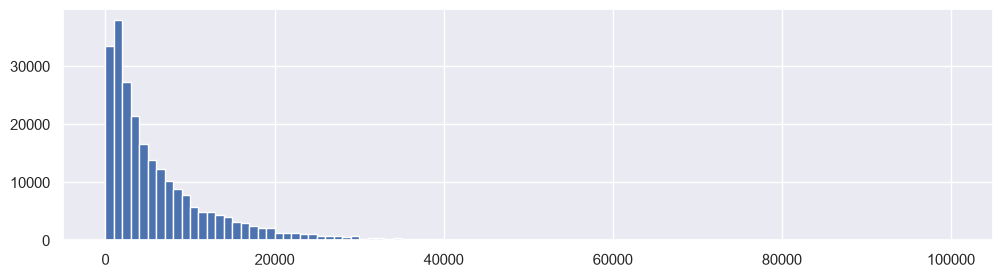

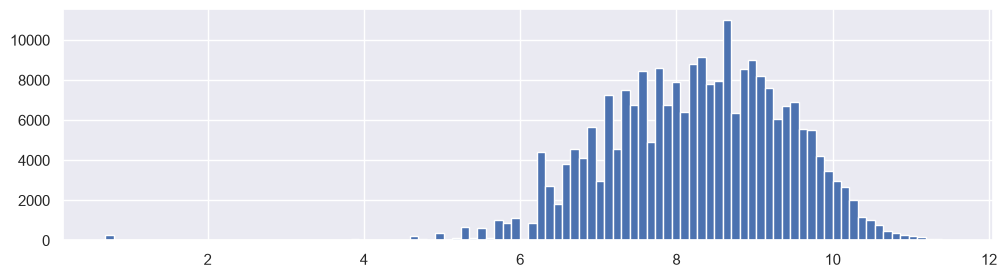

count    241190.000000
mean       6887.741892
std        8024.451993
min           1.000000
25%        1750.000000
50%        4100.000000
75%        8999.000000
max       99999.000000
Name: price, dtype: float64

In [13]:
data['price'].hist(bins=100, figsize=(12, 3))
plt.show()

np.log1p(data['price']).hist(bins=100, figsize=(12, 3))
plt.show()

data['price'].describe()

In [14]:
print('дешевле 100 евро:', (data['price'] <= 100).sum())
print('дороже 50000 евро:', (data['price'] > 50000).sum())

data = data[data['price'] > 100].copy()
data['price'] = np.log1p(data['price'])

data.shape

дешевле 100 евро: 657
дороже 50000 евро: 896


(240533, 10)

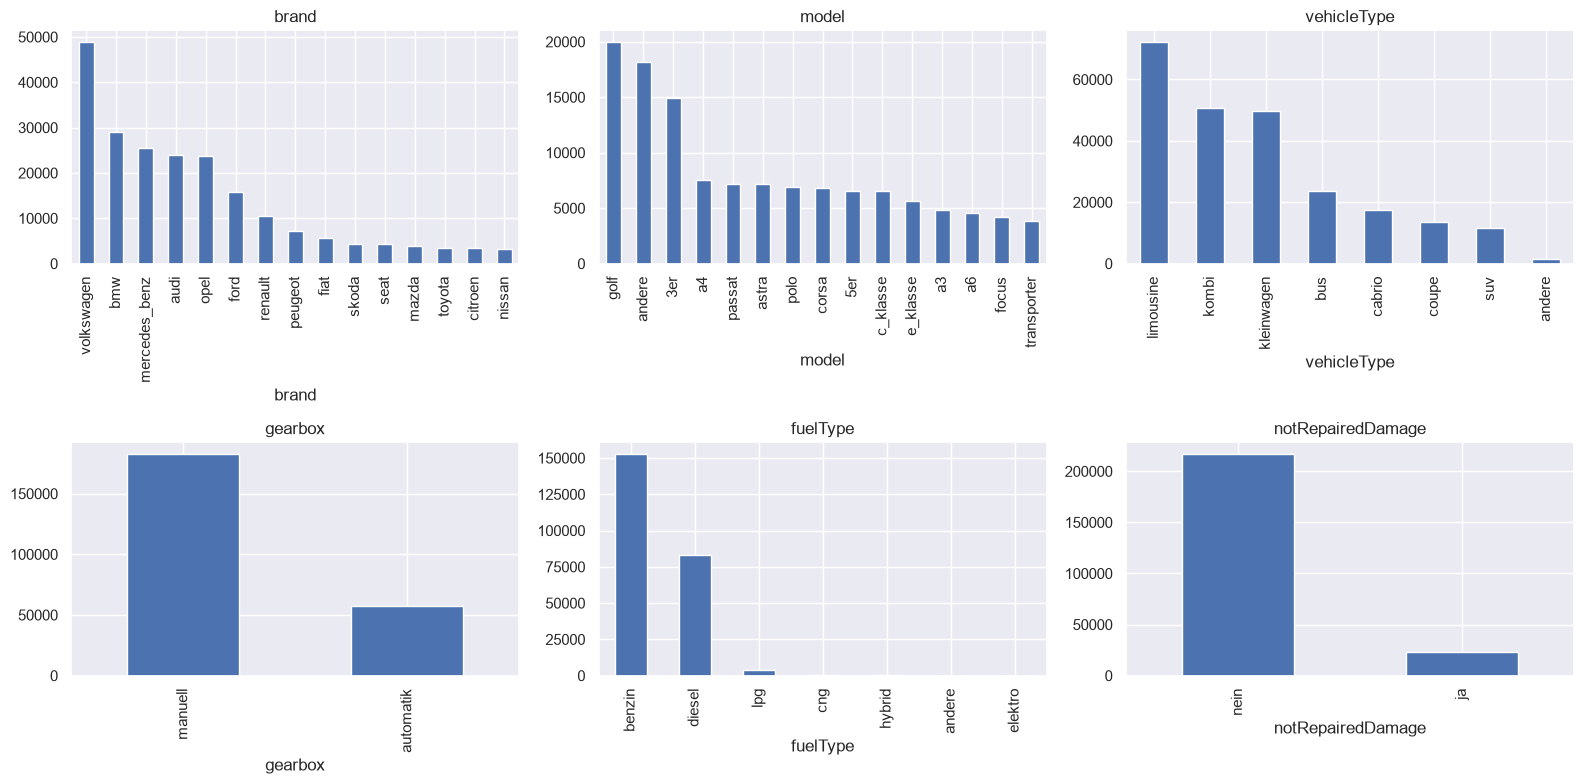

In [15]:
cat_cols = data.select_dtypes('object').columns

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    data[col].value_counts().head(15).plot(kind='bar', ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

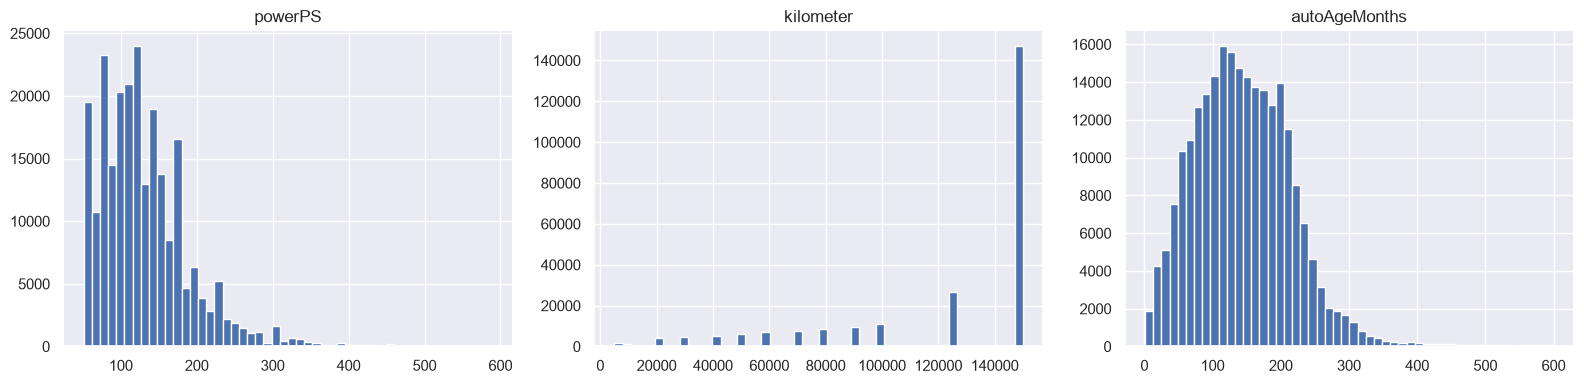

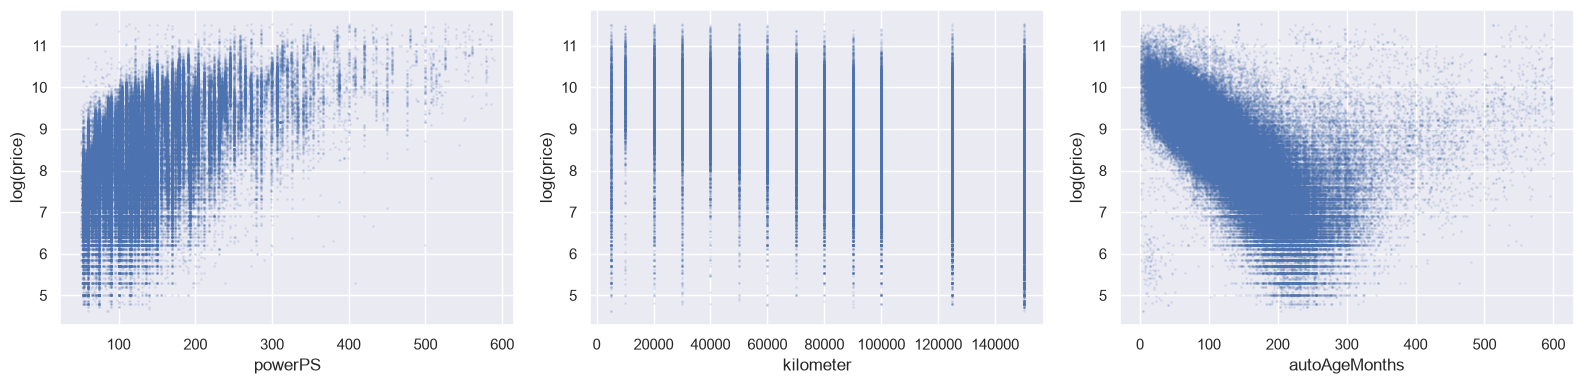

In [16]:
num_cols = ['powerPS', 'kilometer', 'autoAgeMonths']

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    data[col].hist(bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    ax.scatter(data[col], data['price'], s=1, alpha=0.1)
    ax.set_xlabel(col)
    ax.set_ylabel('log(price)')
plt.tight_layout()
plt.show()

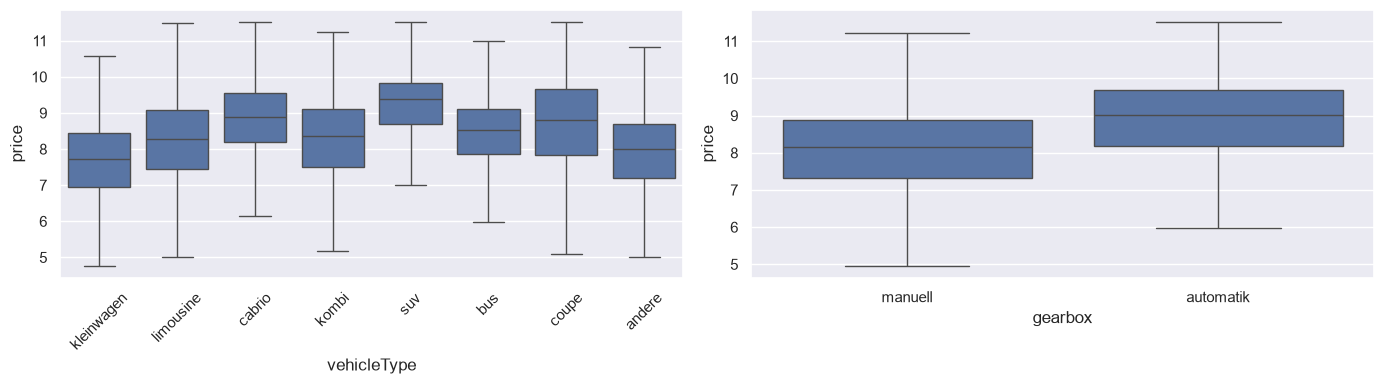

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=data, x='vehicleType', y='price', ax=axes[0], showfliers=False)
axes[0].tick_params(axis='x', rotation=45)
sns.boxplot(data=data, x='gearbox', y='price', ax=axes[1], showfliers=False)
plt.tight_layout()
plt.show()

### Что видно по данным

Цена размазана вправо: медиана около 4100, а 99-й перцентиль уже 37900. На логарифме распределение становится почти симметричным, поэтому беру `log1p(price)`. На сырой цене MSE будет определяться парой самых дорогих машин, а на логе ошибка считается в относительных величинах, что для цен логичнее.

По выбросам: объявлений дешевле 100 евро 657 штук — это заведомый мусор, выкинул. Дорогие машины (больше 50k, их около 900) оставил, это нормальные предложения, с чего бы их удалять.

Дальше по признакам. `powerPS`, `kilometer`, `autoAgeMonths` — числовые, и масштаб у них очень разный (у `kilometer` вообще 13 значений-ступенек), так что без скейлера никак. `brand`, `model`, `vehicleType`, `gearbox`, `fuelType`, `notRepairedDamage` — категориальные, их в one-hot. `bias` — просто столбец единиц, его не трогаем.

`model` самый большой по числу категорий (249), после one-hot это примерно 250 лишних столбцов, но при 240 тысячах строк это не страшно. Логарифмировать `powerPS` и `autoAgeMonths` не стал: по графикам связь с логом цены и так монотонная, а `kilometer` ступенчатый, лог там ничего не изменит.

Разделите признаки на категориальные, числовые и ... все остальное

In [18]:
categorical = ['brand', 'model', 'vehicleType', 'gearbox', 'fuelType', 'notRepairedDamage']
numeric = ['powerPS', 'kilometer', 'autoAgeMonths']
other = []

Добавляем в данные единичную колонку `bias`, чтобы не делать отдельные параметр $b$ для свободного члена модели.

In [19]:
data['bias'] = 1
other += ['bias']

x = data[categorical + numeric + other]
y = data['price']

Теперь вам необходимо разбить данные на обучающую, тестовую и валидационную выборки.

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_tmp, y_train, y_tmp = train_test_split(x, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=42)

print(X_train.shape, X_val.shape, X_test.shape)

(192426, 10) (24053, 10) (24054, 10)


А также сделаем базовую обработку данных, а именно:
* Применим `OneHotEncoding` к категориальным признакам
* Стандартизуем численные признаки с помощью `StandardScaler`
* Остальные признаки трогать не будем, т.к. с ними непонятно что делать

> А почему мы сначала делим данные, а только потом применяем обработку данных? Энкодеры и скейлеры используют информацию о данных: если сделать fit на всем датасете до split, это будет утечка: статистики из val/test попадут в обучение.

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler


column_transformer = ColumnTransformer([
    ('ohe', OneHotEncoder(handle_unknown='ignore'), categorical),
    ('scaling', StandardScaler(), numeric),
    ('other',  'passthrough', other)
])

X_train = column_transformer.fit_transform(X_train)
X_val = column_transformer.transform(X_val)
X_test = column_transformer.transform(X_test)

## Задание 5. Сравнение методов градиентного спуска (1.5 балла)

В этом задании вам предстоит сравнить методы градиентного спуска на подготовленных вами данных из предыдущего задания.

### Задание 5.1. Подбор оптимальной длины шага (0.75 балла)

Подберите по валидационной выборке наилучшую длину шага $\lambda$ для каждого метода с точки зрения ошибки. Для этого сделайте перебор по логарифмической сетке. Для каждого метода посчитайте ошибку на обучающей и тестовой выборках, посчитайте качество по метрике $R^2$, сохраните количество итераций до сходимости.

Все параметры кроме `lambda_` стоит выставить равным значениям по умолчанию.

In [22]:
import warnings
from time import time
warnings.filterwarnings('ignore')
from sklearn.metrics import mean_squared_error, r2_score

methods = {
    'Vanilla': VanillaGradientDescent,
    'SGD': StochasticGradientDescent,
    'SAG': SAGDescent,
    'Momentum': MomentumDescent,
    'Adam': Adam,
}
lambdas = np.logspace(-2, 1, 5)

best_models = {}
rows = []

for name, cls in methods.items():
    best = None
    batches = [32, 512, 1024] if cls is SAGDescent else [None]
    for batch in batches:
        for lam in lambdas:
            kwargs = {'batch_size': batch} if batch else {}
            np.random.seed(42)
            model = CustomLinearRegression(optimizer=cls(lr_schedule=TimeDecayLR(lambda_=lam), **kwargs))
            model.fit(X_train, y_train)

            pred = model.predict(X_val)
            if not np.isfinite(pred).all():
                continue
            val_mse = mean_squared_error(y_val, pred)
            if best is None or val_mse < best[1]:
                best = (lam, val_mse, model, batch)

    lam, val_mse, model, batch = best
    best_models[name] = (lam, model, batch)
    rows.append({
        'метод': name,
        'lambda': lam,
        'batch': batch,
        'MSE train': mean_squared_error(y_train, model.predict(X_train)),
        'MSE test': mean_squared_error(y_test, model.predict(X_test)),
        'R2 train': r2_score(y_train, model.predict(X_train)),
        'R2 test': r2_score(y_test, model.predict(X_test)),
        'итераций': len(model.loss_history) - 1,
    })

metrics = pd.DataFrame(rows).set_index('метод').round(4)
metrics

,lambda,batch,MSE train,MSE test,R2 train,R2 test,итераций
метод,,,,,,,
Vanilla,1.7783,NaN,0.2842,0.2892,0.7711,0.7665,451
SGD,0.3162,NaN,0.3068,0.3129,0.7529,0.7473,1000
SAG,10.0000,1024.0,0.3133,0.3174,0.7477,0.7437,1000
Momentum,1.7783,NaN,0.2665,0.2704,0.7854,0.7816,840
Adam,1.7783,NaN,0.2637,0.2675,0.7877,0.7840,1000


### Задание 5.2. Сравнение методов (0.75 балла)

Постройте график зависимости ошибки на обучающей выборке от номера итерации (все методы на одном графике).

Посмотрите на получившиеся результаты (таблички с метриками и график). Сравните методы между собой.

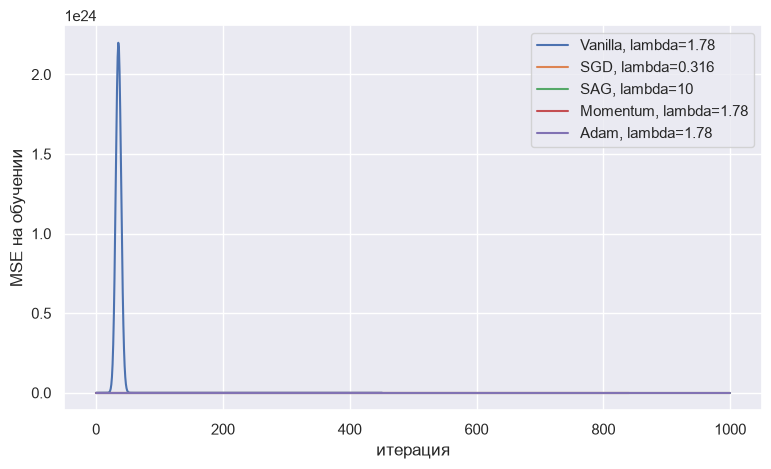

In [23]:
plt.figure(figsize=(9, 5))
for name, (lam, model, batch) in best_models.items():
    plt.plot(model.loss_history, label=f'{name}, lambda={lam:.3g}')
plt.xlabel('итерация')
plt.ylabel('MSE на обучении')
plt.legend()
plt.show()

Лучше всех на тесте Adam и Momentum (R² 0.7840 и 0.7816), у Vanilla 0.7665. Мне кажется, дело в шаге: у них он сглаживается инерцией и адаптивной длиной, и на 310 признаках, где после one-hot матрица плохо обусловлена, они не так скачут.

SGD и SAG почти догнали Vanilla (0.7473 и 0.7437). По графику видно, что оба так и не дошли до конца — упёрлись в 1000 итераций, и кривая на последних шагах ещё падает. SAG при этом успел: с батчем 1024 память заполняется где-то за 190 итераций, так что к тысячной он уже нормально работает. С дефолтным батчем 32 он в переборе давал R² даже отрицательный, поэтому батч ему и подбирал.

Сколько итераций ушло: Vanilla 451, Momentum 840, а Adam, SGD и SAG — по 1000, все трое в лимит.

## Задание 6. Стохастический градиентный спуск и размер батча (1 балл)

В этом задании вам предстоит исследовать влияние размера батча на работу стохастического градиентного спуска.

* Сделайте по несколько запусков (например, $k = 10$) стохастического градиентного спуска на обучающей выборке для каждого размера батча из перебираемого списка. Замерьте время в секундах и количество итераций до сходимости. Посчитайте среднее этих значений для каждого размера батча.
* Постройте график зависимости количества шагов до сходимости от размера батча. _(под сходимостью понимается достижение критерия останова)_
* Постройте график зависимости времени до сходимости от размера батча.

Посмотрите на получившиеся результаты. Какие выводы можно сделать про подбор размера батча для стохастического градиентного спуска?

,шагов,время
batch,,
16,4628.0,5.188
32,4715.6,5.401
64,4200.0,4.825
128,2169.8,2.503
256,1458.8,1.698
512,806.6,1.017
1024,644.0,0.831


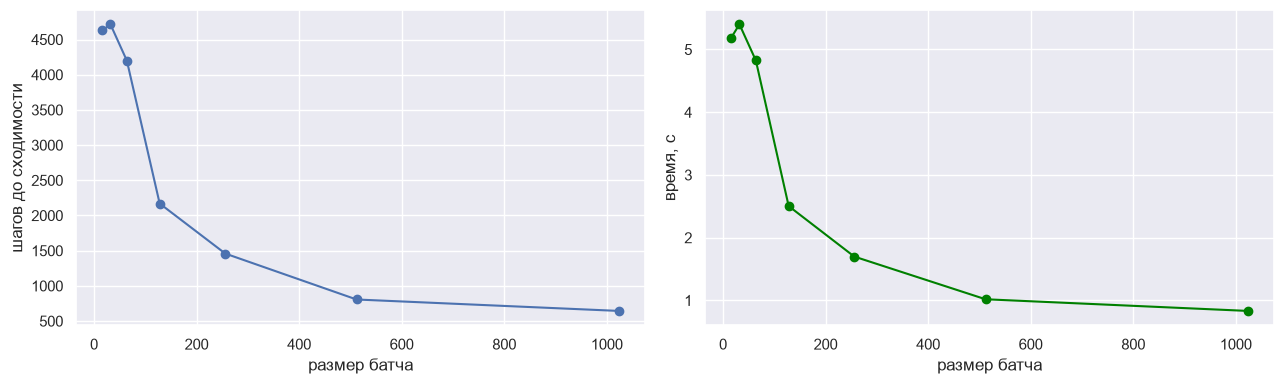

In [24]:
batch_sizes = [16, 32, 64, 128, 256, 512, 1024]
n_runs = 5
lam_sgd = best_models['SGD'][0]

bs_rows = []
for bs in batch_sizes:
    steps, times = [], []
    for rep in range(n_runs):
        np.random.seed(100 + rep)
        start = time()
        model = CustomLinearRegression(optimizer=StochasticGradientDescent(
            lr_schedule=TimeDecayLR(lambda_=lam_sgd), max_iter=10000, batch_size=bs))
        model.fit(X_train, y_train)
        times.append(time() - start)
        steps.append(len(model.loss_history) - 1)
    bs_rows.append({'batch': bs, 'шагов': np.mean(steps), 'время': np.mean(times)})

bs_stats = pd.DataFrame(bs_rows).set_index('batch')
display(bs_stats.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(bs_stats.index, bs_stats['шагов'], marker='o')
axes[0].set_xlabel('размер батча')
axes[0].set_ylabel('шагов до сходимости')
axes[1].plot(bs_stats.index, bs_stats['время'], marker='o', color='green')
axes[1].set_xlabel('размер батча')
axes[1].set_ylabel('время, с')
plt.tight_layout()
plt.show()

**Выводы:**

Гонял SGD с λ=0.3162 (она выбралась в 5.1), батчи от 16 до 1024, по 5 запусков на размер, `max_iter=10000` — иначе сходимость просто не успеть увидеть.

Шагов до сходимости становится меньше с ростом батча, и плато в этом диапазоне не видно: на 16 около 4600, на 128 ~2200, на 512 ~800, на 1024 уже ~640. На 16 и 32 разница вообще в пределах шума (4630 против 4720), потому что там градиент шумный и траектория гуляет.

Время идёт следом: 5.2 с на 16 и 0.83 с на 1024. Причём время на итерацию почти не меняется (~1.1–1.3 мс при любом батче), потому что основное съедает не сам градиент, а пересчёт полного лосса для `loss_history` на каждом шаге. Так что время у меня фактически пропорционально числу шагов.

По времени большой батч тут выигрывает, хотя обычно ждёшь обратного — что шаг подорожает. Но выигрывает он только из-за того, что стоимость итерации от батча не зависит. Если бы лосс не считался целиком каждый шаг, шаг на 1024 стоил бы заметно дороже, и оптимум был бы где-то в середине.

## Задание 7. Регуляризация (0.5 балла)

В этом задании вам предстоит исследовать влияние регуляризации на работу различных методов градиентного спуска. Напомним, регуляризация – это добавка к функции потерь, которая штрафует за норму весов. Мы будем использовать $L_2$-регуляризацию, таким образом функция потерь приобретает следующий вид:

$$
    Q(w) = \dfrac{1}{\ell} \sum\limits_{i=1}^{\ell} (a_w(x_i) - y_i)^2 + \dfrac{\mu}{2} \| w \|^2
$$

Допишите класс `linear_regression.L2Regularization`, следуя интерфейсу и докуметации.

Используя регуляризованный лосс в эксприментах, найдите лучшие параметры обучения с регуляризацией аналогично 5 заданию. Будем подбирать длину шага $\lambda$ (`lambda_`) и коэффициент регуляризации $\mu$ (`mu`).

Сравните для каждого метода результаты с регуляризацией и без регуляризации (нужно опять сохранить ошибку и качество по метрике $R^2$ на обучающей и тестовой выборках и количество итераций до сходимости).

Постройте для каждого метода график со значениями функции потерь MSE с регуляризацией и без регуляризации (всего должно получиться 5 графиков).

Посмотрите на получившиеся результаты. Какие можно сделать выводы, как регуляризация влияет на сходимость? Как изменилось качество на обучающей выборке? На тестовой? Чем вы можете объяснить это?

In [25]:
mus = [1e-3, 1e-2, 1e-1]

reg_models = {}
reg_rows = []

for name, cls in methods.items():
    lam0, _, batch0 = best_models[name]
    best = None
    for mu in mus:
        for lam in (lam0, lam0 * 3):
            kwargs = {'batch_size': batch0} if batch0 else {}
            np.random.seed(42)
            model = CustomLinearRegression(
                optimizer=cls(lr_schedule=TimeDecayLR(lambda_=lam), **kwargs),
                loss_function=L2Regularization(MSELoss(), mu_rate=mu))
            model.fit(X_train, y_train)

            pred = model.predict(X_val)
            if not np.isfinite(pred).all():
                continue

            val_mse = mean_squared_error(y_val, pred)
            if not np.isfinite(val_mse):
                continue
            if best is None or val_mse < best[0]:
                best = (val_mse, mu, lam, model)

    val_mse, mu, lam, model = best
    reg_models[name] = (mu, lam, model)
    reg_rows.append({
        'метод': name,
        'mu': mu,
        'lambda': lam,
        'val MSE': val_mse,
        'R2 train': r2_score(y_train, model.predict(X_train)),
        'R2 test': r2_score(y_test, model.predict(X_test)),
        'итераций': len(model.loss_history) - 1,
    })

reg_metrics = pd.DataFrame(reg_rows).set_index('метод').round(4)
display(reg_metrics)

comparison = pd.DataFrame({
    'mu': reg_metrics['mu'],
    'R2 train без L2': metrics['R2 train'],
    'R2 train с L2': reg_metrics['R2 train'],
    'R2 test без L2': metrics['R2 test'],
    'R2 test с L2': reg_metrics['R2 test'],
    'итераций без L2': metrics['итераций'],
    'итераций с L2': reg_metrics['итераций'],
}).round(4)
comparison

,mu,lambda,val MSE,R2 train,R2 test,итераций
метод,,,,,,
Vanilla,0.001,1.7783,0.2822,0.7704,0.7656,415
SGD,0.001,0.3162,0.3035,0.7528,0.7471,1000
SAG,0.001,30.0000,0.2851,0.7682,0.7637,1000
Momentum,0.001,1.7783,0.2669,0.7827,0.7788,401
Adam,0.001,1.7783,0.2657,0.7834,0.7796,1000


,mu,R2 train без L2,R2 train с L2,R2 test без L2,R2 test с L2,итераций без L2,итераций с L2
метод,,,,,,,
Vanilla,0.001,0.7711,0.7704,0.7665,0.7656,451,415
SGD,0.001,0.7529,0.7528,0.7473,0.7471,1000,1000
SAG,0.001,0.7477,0.7682,0.7437,0.7637,1000,1000
Momentum,0.001,0.7854,0.7827,0.7816,0.7788,840,401
Adam,0.001,0.7877,0.7834,0.7840,0.7796,1000,1000


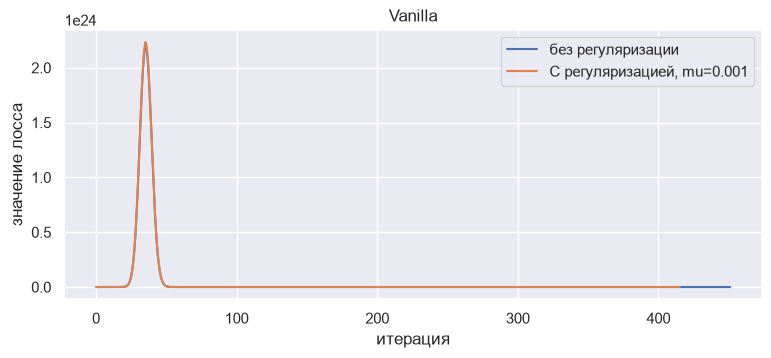

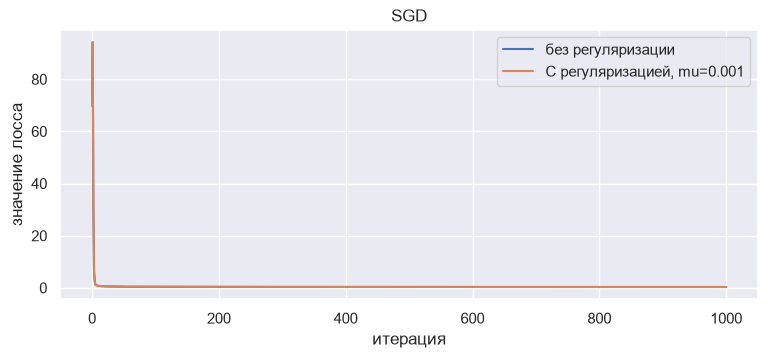

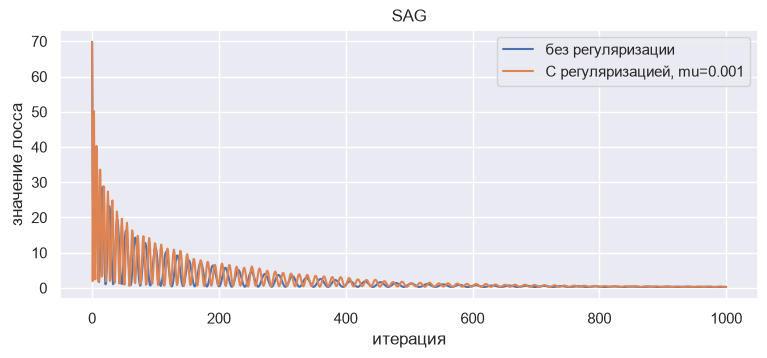

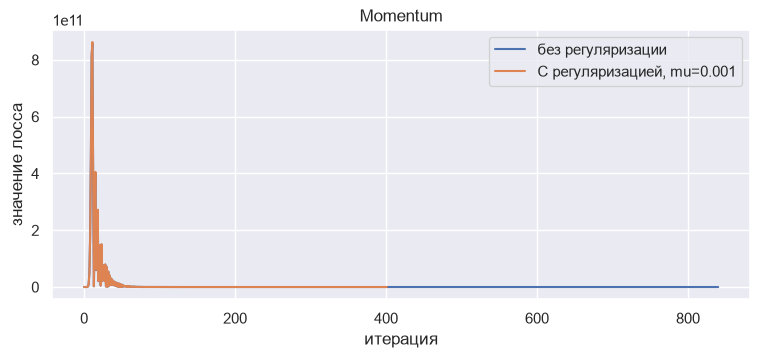

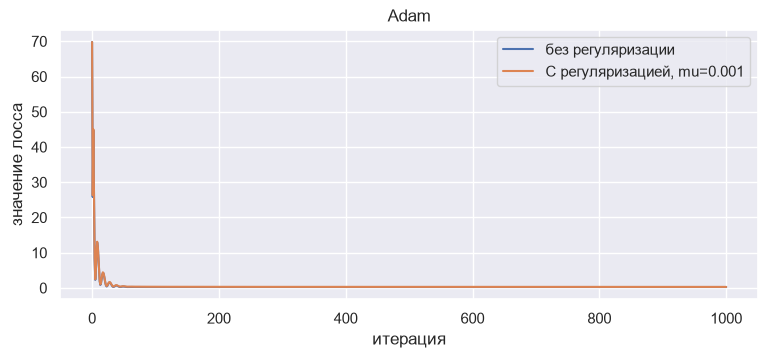

In [26]:
for name, (mu, lam, model) in reg_models.items():
    plt.figure(figsize=(9, 3.5))
    plt.plot(best_models[name][1].loss_history, label='без регуляризации')
    plt.plot(model.loss_history, label=f'C регуляризацией, mu={mu:g}')
    plt.title(name)
    plt.xlabel('итерация')
    plt.ylabel('значение лосса')
    plt.legend()
    plt.show()

**Вывод:**

Перебирал μ по 1e-3, 1e-2 и 1e-1, λ брал из 5.1 и она же ×3. Выбирал по MSE на валидации.

Везде выиграл самый маленький μ, 1e-3. На нём разница с обучением без регуляризации почти пропадает: R² на тесте 0.7656 против 0.7665 у Vanilla, 0.7471 против 0.7473 у SGD, 0.7788 против 0.7816 у Momentum, 0.7796 против 0.7840 у Adam. Большие μ валидации не понравились вообще — веса стягиваются к нулю и модель недоучивается.

Из общего ряда выбивается SAG: с L2 он стал лучше (0.7637 против 0.7437). Но я не думаю, что дело в самом штрафе — там вместе с μ подобрался и шаг, λ=30 вместо 10, а SAG к шагу очень чувствителен. Скорее всего, выигрыш от этого.

Сходимость: у Momentum итераций стало 401 против 840, у Vanilla 415 против 451. Штраф не даёт весам разъезжаться, «овраги» сглаживаются, шаги перестают скакать, и условие по норме разности весов выполняется раньше. У SGD, SAG и Adam итерации всё равно упираются в 1000, там разницы не видно.

Выигрыша на тесте при этом так и не появилось. Мне кажется, переобучаться здесь просто не на чем — 192 тысячи объектов на 310 признаков, модель не запоминает выборку. Так что L2 тут больше про скорость, чем про качество.

## Задание 8. Альтернативные функции потерь (1 балл)

В этом задании вам предстоит использовать другую функцию потерь для нашей задачи регрессии. В качестве функции потерь мы выбрали **LogCosh** и **HuberLoss**:

$$
    L(y, a)
    =
    \log\left(\cosh(a - y)\right).
$$

$$
L_{\text{Huber}}(y, a) = \frac{1}{n} \sum_{i=1}^{n}
\begin{cases}
   \frac{1}{2} (a_i - y_i)^2, & \text{если } |a_i - y_i| < \delta, \\
   \delta \cdot |a_i - y_i| - \frac{1}{2} \delta^2, & \text{если } |a_i - y_i| \geq \delta,
\end{cases}
$$

Самостоятельно продифференцируйте данные функции потерь чтобы найти их градиенты _(требуется показать не только результат, но и промежуточные вычисления)_:

**Решение:**

Считаем $a_i = \langle x_i, w \rangle$, $L = \frac{1}{n}\sum_{i=1}^{n}\ell(a_i, y_i)$.

**LogCosh**: $\ell(a, y) = \log\cosh(a-y)$. Так как $(\cosh z)' = \sinh z$, то
$$
\frac{\partial \ell}{\partial a} = \frac{\sinh(a-y)}{\cosh(a-y)} = \tanh(a-y),
$$
дальше цепочка: $\frac{\partial \ell}{\partial w_j} = \frac{\partial \ell}{\partial a}\cdot\frac{\partial a}{\partial w_j} = \tanh(a-y)\,x_j$. В матричном виде:
$$
\nabla_w L = \frac{1}{n}X^T\tanh(Xw-y).
$$

**Huber**: обозначим $r = a - y$. При $|r|<\delta$ имеем $\ell = \frac{r^2}{2}$ и $\frac{\partial \ell}{\partial r} = r$; при $|r|\ge\delta$ имеем $\ell = \delta|r| - \frac{\delta^2}{2}$ и $\frac{\partial \ell}{\partial r} = \delta\cdot\mathrm{sign}(r)$ (константа $\frac{\delta^2}{2}$ уходит, а $(|r|)' = \mathrm{sign}(r)$). Цепочка та же:
$$
\nabla_w L = \frac{1}{n}X^Tg,\quad g_i = \begin{cases} r_i, & |r_i|<\delta,\\ \delta\,\mathrm{sign}(r_i), & |r_i|\ge\delta. \end{cases}
$$

Программно реализуйте функции потерь и их градиенты для LogCosh и HuberLoss в файле `linear_regression.py`. После этого обучите все пять методов градиентного спуска (без регуляризации) с этими лоссами аналогично заданию 5 и сравните качество с результатами из задания 5, где использовался MSE.

Имплементировать эти функции потерь необходимо при помощи наследования от `linear_regression.LossFunction` и имплементирования всех абстрактных методов. Аналитическое решение для этих функций выводить и имплементировать не требуется.



In [27]:
losses = {'LogCosh': LogCoshLoss(), 'Huber': HuberLoss()}

task8_rows = []
for loss_name, loss in losses.items():
    for name, cls in methods.items():
        lam0, _, batch0 = best_models[name]
        best = None
        for lam in (lam0, lam0 * 3):
            kwargs = {'batch_size': batch0} if batch0 else {}
            np.random.seed(42)
            model = CustomLinearRegression(
                optimizer=cls(lr_schedule=TimeDecayLR(lambda_=lam), **kwargs),
                loss_function=loss)
            model.fit(X_train, y_train)

            pred = model.predict(X_val)
            if not np.isfinite(pred).all():
                continue
            val_mse = mean_squared_error(y_val, pred)
            if best is None or val_mse < best[1]:
                best = (lam, val_mse, model)

        lam, val_mse, model = best
        task8_rows.append({
            'лосс': loss_name,
            'метод': name,
            'lambda': lam,
            'MSE test': mean_squared_error(y_test, model.predict(X_test)),
            'R2 train': r2_score(y_train, model.predict(X_train)),
            'R2 test': r2_score(y_test, model.predict(X_test)),
            'итераций': len(model.loss_history) - 1,
        })

loss_metrics = pd.DataFrame(task8_rows).set_index(['лосс', 'метод']).round(4)
loss_metrics

lambda  MSE test  R2 train  R2 test  итераций
лосс    метод                                                   
LogCosh Vanilla    5.3348    0.3018    0.7617   0.7563       534
        SGD        0.9487    0.3265    0.7428   0.7363      1000
        SAG       30.0000    0.2896    0.7706   0.7661      1000
        Momentum   5.3348    0.2816    0.7771   0.7726       997
        Adam       5.3348    0.2775    0.7800   0.7759       765
Huber   Vanilla    5.3348    0.3021    0.7615   0.7560       574
        SGD        0.9487    0.3255    0.7436   0.7372      1000
        SAG       30.0000    0.3124    0.7521   0.7477      1000
        Momentum   5.3348    0.2829    0.7763   0.7715      1000
        Adam       5.3348    0.2788    0.7790   0.7748       712

Сравниваю с MSE из 5.1 (там на тесте было 0.7665 у Vanilla, 0.7473 у SGD, 0.7437 у SAG, 0.7816 у Momentum, 0.7840 у Adam).

Честно говоря, принципиальной разницы не увидел. LogCosh и Huber дают 0.7563 и 0.7560 у Vanilla, 0.7726 и 0.7715 у Momentum, 0.7759 и 0.7748 у Adam — те же цифры с точностью до третьего знака. У SAG вышло лучше (0.7661 и 0.7477), но там опять другой λ (30 вместо 10), так что сравнение не совсем честное. Хуже всех SGD — 0.7363 и 0.7372 против 0.7473 у MSE.

Заметил, что почти везде перебор выбрал λ в три раза больше, чем для MSE (5.33 против 1.78). Похоже, из-за того, что производные у log cosh и у Huber ограничены (tanh и δ соответственно), шаг получается меньше, и его приходится добирать длиной шага.

Почему разницы с MSE почти нет: мусорные цены я выкинул ещё на этапе EDA, и больших выбросов в таргете осталось мало. LogCosh и Huber как раз и нужны, чтобы редкие огромные ошибки не тянули на себя всё обучение, а тянуть стало нечего, так что работают они как MSE, только помягче.